# WindGuard: Wind-Turbine Failure Prediction Using SCADA Data

**Project objective.** Evaluate whether 10-minute turbine measurements—including temperature, pressure, wind, and power channels—can provide an early warning of a failure up to seven days in advance.

**Notebook workflow**

| Stage | Analysis |
|---|---|
| 1. Data loading and preparation | Load the dataset and aggregate observations into hourly records |
| 2. Exploratory analysis | Assess data quality, operating stops, failure events, power curves, and sensor relationships |
| 3. Failure labelling | Identify pre-event windows and normal operating periods using the defined seven-day horizon |
| 4. Feature engineering | Model expected sensor behaviour and calculate deviations from the expected values |
| 5. Model development and training | Compare Logistic Regression, SVM, Naive Bayes, Random Forest, Gradient Boosting, ANN, and Isolation Forest |
| 6. Model evaluation and validation | Review accuracy, precision, recall, F1, PR-AUC, ROC-AUC, confusion matrices, confidence intervals, and cross-validation |
| 7. Remaining useful life and cross-farm generalisation | Estimate the days left before a failure, and test how well the models transfer to a second farm |
| 8–9. Results summary and dashboard export | Save summary tables and prepare the files consumed by the Streamlit dashboard |

**Data and interpretation.** The notebook reads the Kelmarsh and Penmanshiel CSV files stored in the project's `data/raw/` folder (no Google Drive needed). Note that the file headers describe the turbines as "-like" (e.g. *Senvion MM92-like*) and the ground-truth CSVs next to them contain simulation parameters (`amp`, `gamma`, `lead_days`), so the origin of these files should be confirmed before the metrics are described as performance on operational turbines.

## 1. Data Loading and Preparation
### 1.1 Settings

In [1]:
import os, re, glob, subprocess, sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# The CSV files are in the project's data folder:  data/raw/kelmarsh  and  data/raw/penmanshiel
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "data", "raw")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                                        # walk up from the notebook folder to the project root
DATA_ROOT = os.path.join(ROOT, "data", "raw").replace("\\", "/")        # folder that contains the kelmarsh/ and penmanshiel/ folders
OUT = os.path.join(ROOT, "outputs").replace("\\", "/")                  # result tables are saved here
os.makedirs(OUT, exist_ok=True)

TRAIN_YEARS, VAL_YEAR, TEST_YEAR = [2016, 2017, 2018, 2019, 2020], 2021, 2022   # train / validation / test split by year
PRE_DAYS = 7            # an hour is "pre-failure" if a failure happens within the next 7 days
print("Reading data from:", DATA_ROOT)


Reading data from: M:/ML Sem 5/project/WindGuard-Wind-Turbine-Failure-Precursor-Detection/data/raw


### 1.2 Check that the files are there

In [2]:
for farm in ["Kelmarsh", "Penmanshiel"]:
    n_scada = len(glob.glob(f"{DATA_ROOT}/**/{farm}_SCADA_*/Turbine_Data_*.csv", recursive=True))
    n_status = len(glob.glob(f"{DATA_ROOT}/**/{farm}_SCADA_*/Status_*.csv", recursive=True))
    print(f"{farm}: {n_scada} SCADA files, {n_status} status files")
    if n_scada == 0:
        print("No files found. Check that the CSV folders are inside data/raw/ (see DATA_ROOT above).")


Kelmarsh: 42 SCADA files, 42 status files
Penmanshiel: 56 SCADA files, 56 status files


All files are found: **Kelmarsh** has 6 turbines × 7 years = 42 SCADA files and 42 status files, and **Penmanshiel** has 14 turbines × 4 years = 56 of each. Every SCADA file is paired with a status log.

### 1.3 Which columns do we use?
* **Drivers** = operating conditions (wind, power, rotor speed, outside temperature). They explain why a part is warm or cold.
* **Sensors** = the component readings we watch for trouble (gearbox oil, bearings, stator, pressures, vibration).

In [3]:
DRIVERS = ["Wind speed (m/s)", "Power (kW)", "Rotor speed (RPM)", "Nacelle ambient temperature (°C)"]
SENSORS = ["Gear oil temperature (°C)", "Front bearing temperature (°C)", "Generator bearing front temperature (°C)",
           "Generator bearing rear temperature (°C)", "Stator temperature 1 (°C)", "Transformer temperature (°C)",
           "Nacelle temperature (°C)", "Gear oil inlet pressure (bar)", "Hydraulic oil pressure (bar)",
           "Tower Acceleration X (mm/ss)", "Tower Acceleration Y (mm/ss)", "Blade angle (pitch position) A (°)"]
WANTED = set(DRIVERS + SENSORS + ["Date and time"])
pd.DataFrame({"type": ["driver"] * len(DRIVERS) + ["sensor"] * len(SENSORS), "column": DRIVERS + SENSORS})

,type,column
0,driver,Wind speed (m/s)
1,driver,Power (kW)
2,driver,Rotor speed (RPM)
3,driver,Nacelle ambient temperature (°C)
4,sensor,Gear oil temperature (°C)
5,sensor,Front bearing temperature (°C)
6,sensor,Generator bearing front temperature (°C)
7,sensor,Generator bearing rear temperature (°C)
8,sensor,Stator temperature 1 (°C)
9,sensor,Transformer temperature (°C)


The 16 columns we use: 4 **drivers** (wind, power, rotor speed, outside temperature) that describe the operating conditions, and 12 **sensors** (temperatures, pressures, vibration, blade angle) that we watch for signs of trouble.

### 1.4 Helper functions to read the files
The CSV files start with a few comment lines, so we first find the line that holds the column names.

In [4]:
def read_with_header(path, header_start):
    with open(path, encoding="utf-8") as f:
        skip = next(i for i, line in enumerate(f) if line.startswith(header_start))
    df = pd.read_csv(path, skiprows=skip)
    df.columns = [c.replace("# ", "").strip() for c in df.columns]
    return df

def turbine_number(path):
    return int(re.search(r"_(\d+)_\d{4}-\d{2}-\d{2}_-_", os.path.basename(path)).group(1))

def load_farm(farm):
    """Return (hourly sensor table, status table) for one wind farm."""
    tables, stops = [], []
    for path in sorted(glob.glob(f"{DATA_ROOT}/**/{farm}_SCADA_*/Turbine_Data_*.csv", recursive=True)):
        df = read_with_header(path, "# Date and time")
        df = df[[c for c in df.columns if c in WANTED]]
        df["Date and time"] = pd.to_datetime(df["Date and time"])
        hourly = df.set_index("Date and time").resample("1h").mean()      # 10-minute readings -> hourly average
        hourly["turbine"] = turbine_number(path)
        tables.append(hourly.reset_index())
    for path in sorted(glob.glob(f"{DATA_ROOT}/**/{farm}_SCADA_*/Status_*.csv", recursive=True)):
        st = read_with_header(path, "# Timestamp start")
        st["turbine"] = turbine_number(path)
        stops.append(st)
    scada, status = pd.concat(tables, ignore_index=True), pd.concat(stops, ignore_index=True)
    status["Timestamp start"] = pd.to_datetime(status["Timestamp start"])
    status["Timestamp end"] = pd.to_datetime(status["Timestamp end"])
    return scada, status

### 1.5 Load Kelmarsh

In [5]:
kel, kel_status = load_farm("Kelmarsh")
print(f"Hourly sensor table: {kel.shape[0]:,} rows x {kel.shape[1]} columns | status log: {len(kel_status):,} events")
kel.head()

Hourly sensor table: 368,208 rows x 18 columns | status log: 1,287 events


,Date and time,Wind speed (m/s),Power (kW),Rotor speed (RPM),Nacelle ambient temperature (°C),Gear oil temperature (°C),Front bearing temperature (°C),Generator bearing front temperature (°C),Stator temperature 1 (°C),Blade angle (pitch position) A (°),Gear oil inlet pressure (bar),Hydraulic oil pressure (bar),Tower Acceleration X (mm/ss),Generator bearing rear temperature (°C),Transformer temperature (°C),Nacelle temperature (°C),Tower Acceleration Y (mm/ss),turbine
0,2016-01-01 00:00:00,6.126000,424.603000,9.163500,0.141667,26.565167,18.995667,20.372000,17.935500,1.073167,2.489833,171.038500,54.388833,21.440000,11.481333,6.148333,44.298500,1
1,2016-01-01 01:00:00,7.729333,681.711167,11.781333,1.257000,27.240000,22.262667,22.147167,22.777167,1.064833,2.634167,170.667833,62.607333,23.195333,11.624167,6.858333,49.066000,1
2,2016-01-01 02:00:00,8.897167,1105.490667,13.289500,1.767000,32.654667,27.502333,29.037833,35.837000,0.951667,2.723000,171.210833,67.666167,29.964000,15.913833,9.024167,54.364333,1
3,2016-01-01 03:00:00,8.872000,1167.259667,13.262000,1.060833,34.716333,28.836667,29.955000,37.236500,1.049333,2.660500,172.477000,70.409167,30.810167,18.024000,9.271167,58.108167,1
4,2016-01-01 04:00:00,6.351667,440.316833,10.928667,0.794333,31.866833,25.975500,24.310833,21.648333,1.024167,2.575333,171.885667,64.814500,25.427000,16.838667,7.757500,41.289667,1


The 10-minute readings of all 6 turbines are now one **hourly table of 368,208 rows**, together with a status log of 1,287 events (stops, warnings, service visits). The first rows show a typical hour: wind, power, rotor speed and the component temperatures.

## 2. Exploratory Data Analysis (EDA)
### 2.1 Data quality: how complete is the data?

In [6]:
quality = pd.DataFrame({
    "missing %": (kel[DRIVERS + SENSORS].isna().mean() * 100).round(2),
    "min": kel[DRIVERS + SENSORS].min().round(1),
    "max": kel[DRIVERS + SENSORS].max().round(1)})
print(f"{kel.turbine.nunique()} turbines, {kel['Date and time'].min():%Y-%m-%d} to {kel['Date and time'].max():%Y-%m-%d}")
quality

6 turbines, 2016-01-01 to 2022-12-31


,missing %,min,max
Wind speed (m/s),0.86,0.0,24.0
Power (kW),0.86,-13.4,2101.8
Rotor speed (RPM),0.86,0.0,15.0
Nacelle ambient temperature (°C),0.86,-9.5,29.3
Gear oil temperature (°C),0.86,9.6,109.1
Front bearing temperature (°C),0.86,0.6,81.2
Generator bearing front temperature (°C),0.86,4.1,103.9
Generator bearing rear temperature (°C),0.86,5.1,81.3
Stator temperature 1 (°C),0.86,3.3,147.0
Transformer temperature (°C),0.86,-2.6,109.3


About **0.86 %** of hours are missing for almost every column (Tower Acceleration Y has 2.5 %), so the data is nearly complete. The min/max columns show plausible ranges, for example gear oil temperature 9.6-109 °C and power up to about 2,100 kW, which fits a 2 MW turbine.

### 2.2 Why does the turbine stop? (status log)

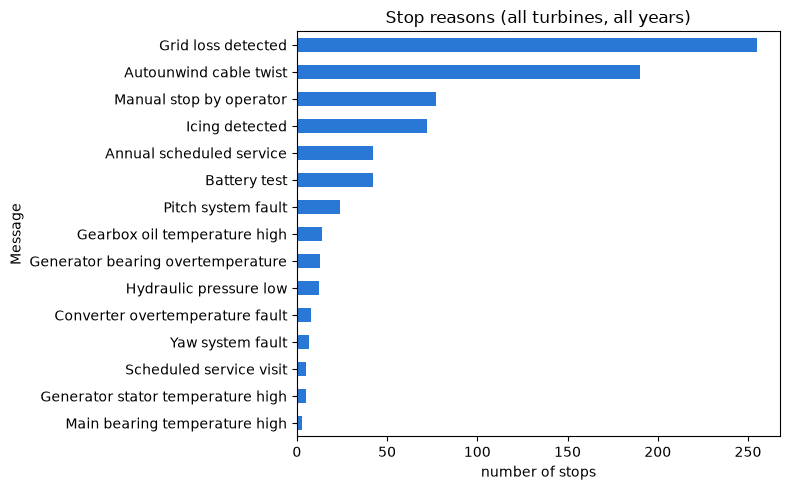

In [7]:
stop_reasons = kel_status[kel_status["Status"] == "Stop"]["Message"].value_counts()
stop_reasons.sort_values().plot.barh(figsize=(8, 5), color="#2a78d6")
plt.xlabel("number of stops"); plt.title("Stop reasons (all turbines, all years)"); plt.tight_layout(); plt.show()

Most stops are routine: **grid loss, cable untwisting, manual stops, icing and scheduled service**. Real component faults (pitch, gearbox oil temperature, generator bearing, hydraulic pressure and so on) are far rarer, which is why they are the events we try to predict.

### 2.3 Power curve: power produced for each wind speed
A healthy turbine follows one clean curve; the cut-in is near 3 m/s and the rated power is 2050 kW.

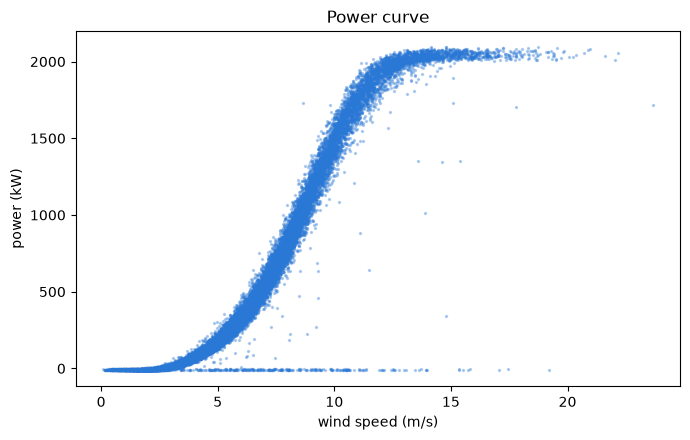

In [8]:
s = kel.dropna(subset=["Wind speed (m/s)", "Power (kW)"]).sample(20000, random_state=0)
plt.figure(figsize=(7, 4.5))
plt.scatter(s["Wind speed (m/s)"], s["Power (kW)"], s=2, alpha=0.3, color="#2a78d6")
plt.xlabel("wind speed (m/s)"); plt.ylabel("power (kW)"); plt.title("Power curve"); plt.tight_layout(); plt.show()

Healthy turbines follow one clear S-shaped curve: no power below about 3 m/s, a steep rise, and a flat top at about 2,000 kW above about 12 m/s. The dots along the bottom are hours where the turbine produced nothing despite wind (stopped), and a few stray points are unusual hours.

### 2.4 Correlation between sensors
Blocks of high correlation mean sensors move together (usually because they all follow the load).

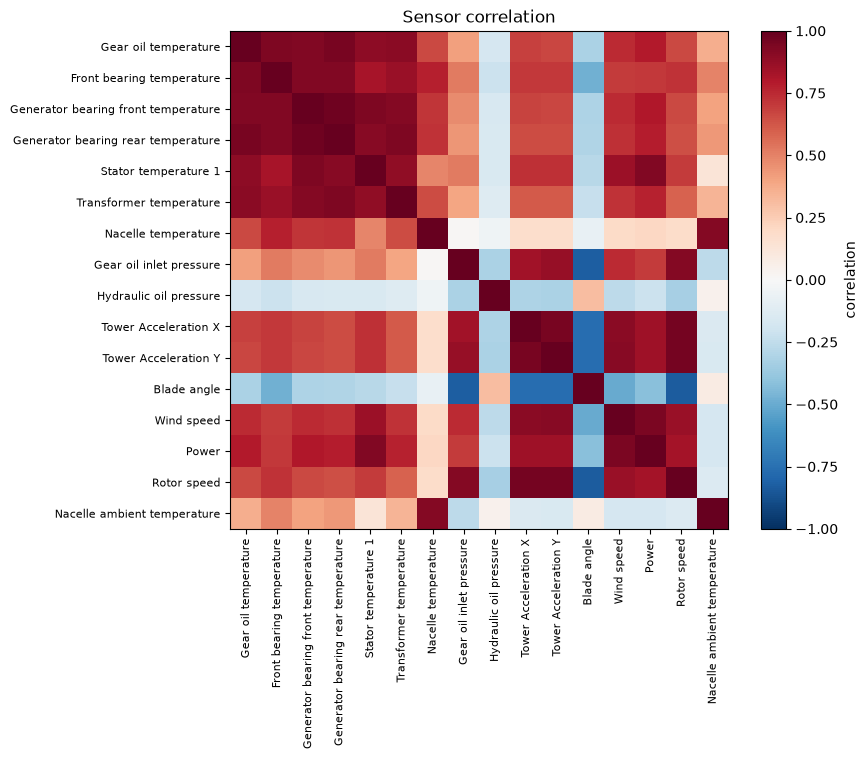

In [9]:
corr = kel[SENSORS + DRIVERS].corr()
plt.figure(figsize=(9, 7.5))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(corr)), [c.split(" (")[0] for c in corr.columns], rotation=90, fontsize=8)
plt.yticks(range(len(corr)), [c.split(" (")[0] for c in corr.columns], fontsize=8)
plt.colorbar(label="correlation"); plt.title("Sensor correlation"); plt.tight_layout(); plt.show()

The temperature sensors (gear oil, bearings, stator, transformer) are strongly correlated with each other and with wind, power and rotor speed, so they mostly move together because of **how hard the turbine works**. This is why we compare each sensor with its expected value instead of using raw readings.

## 3. Failure Labelling: Which Hours Come Before a Failure?
### 3.1 Find the failures
Rule used here (simple and easy to change): a **failure** is a status event with `Status = Stop` and `IEC category = Forced outage`. Stops of the same turbine less than 7 days apart count as one failure.

In [10]:
def find_failures(status):
    stops = status[(status["Status"] == "Stop") & (status["IEC category"] == "Forced outage")]
    stops = stops.sort_values(["turbine", "Timestamp start"]).copy()
    gap = stops.groupby("turbine")["Timestamp start"].diff()
    stops["episode"] = (gap.isna() | (gap > pd.Timedelta(days=7))).cumsum()       # new failure when the gap is > 7 days
    return stops.groupby("episode").agg(turbine=("turbine", "first"), t_fail=("Timestamp start", "first"),
                                        t_end=("Timestamp end", "last"), message=("Message", "first")).reset_index(drop=True)

kel_failures = find_failures(kel_status)
print(len(kel_failures), "failures found")
kel_failures.groupby(kel_failures.t_fail.dt.year).size().rename("failures per year").to_frame().T

85 failures found


t_fail,2016,2017,2018,2019,2020,2021,2022
failures per year,5,11,13,12,16,15,13


**85 failures** were found across the 6 turbines over 7 years: 5 in 2016 and 11-16 per year after that, so 13 fall in the 2022 test year.

### 3.2 When did the failures happen?

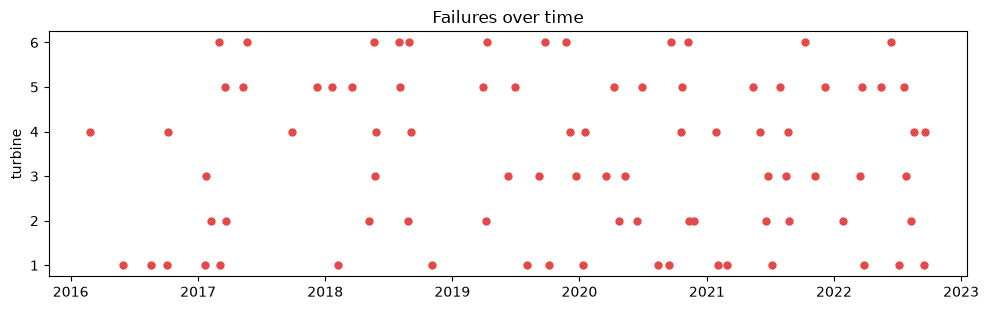

In [11]:
plt.figure(figsize=(10, 3.2))
plt.scatter(kel_failures.t_fail, kel_failures.turbine, s=25, color="#e34948")
plt.yticks(sorted(kel_failures.turbine.unique())); plt.ylabel("turbine"); plt.title("Failures over time"); plt.tight_layout(); plt.show()

Failures are spread over all turbines and years with no obvious pattern, so every turbine and year contributes some events to learn from or test on.

### 3.3 Label every hour
* `label = 1` (pre-failure): the next failure is less than 7 days away.
* `label = 0` (normal): everything else.
* **Skipped** hours: the turbine is stopped (any stop) or it is the first day after a failure; sensor values there are not meaningful.

In [12]:
def add_labels(scada, failures, status):
    scada = scada.sort_values(["turbine", "Date and time"]).reset_index(drop=True)
    scada["label"], scada["episode"], scada["days_to_failure"], scada["skip"] = 0, -1, np.nan, False
    for turbine, rows in scada.groupby("turbine"):
        t, idx = rows["Date and time"], rows.index
        for _, st in status[(status.turbine == turbine) & (status.Status == "Stop")].iterrows():
            scada.loc[idx[((t + pd.Timedelta(hours=1) > st["Timestamp start"]) & (t < st["Timestamp end"])).to_numpy()], "skip"] = True
        for episode, f in failures[failures.turbine == turbine].iterrows():
            window = ((t >= f.t_fail - pd.Timedelta(days=PRE_DAYS)) & (t < f.t_fail)).to_numpy()
            scada.loc[idx[window], "label"] = 1
            scada.loc[idx[window], "episode"] = episode
            scada.loc[idx[window], "days_to_failure"] = (f.t_fail - t[window]).dt.total_seconds() / 86400
            after = ((t >= f.t_fail) & (t < f.t_end + pd.Timedelta(days=1))).to_numpy()      # stopped + one extra day
            scada.loc[idx[after], "skip"] = True
    return scada

kel = add_labels(kel, kel_failures, kel_status)
usable = kel[~kel.skip]
usable.groupby(usable["Date and time"].dt.year).agg(hours=("label", "size"), pre_failure_hours=("label", "sum"),
                                                      pre_failure_pct=("label", lambda x: round(x.mean() * 100, 1)))

,hours,pre_failure_hours,pre_failure_pct
Date and time,,,
2016,52059,835,1.6
2017,51489,1829,3.6
2018,51171,2145,4.2
2019,51324,1999,3.9
2020,51302,2658,5.2
2021,51246,2480,4.8
2022,50980,2153,4.2


Between **1.6 % and 5.2 % of usable hours per year are pre-failure** (label = 1), so the classes are heavily imbalanced. A model that always says "normal" would look about 95 % accurate but be useless, which is why we look at precision, recall and PR-AUC next to accuracy. (Hours while the turbine is stopped, and the day after a failure, are excluded.)

### 3.4 What does a failure look like in the raw data?
Gearbox oil temperature in the 14 days before one gearbox failure. The vertical line is the failure.

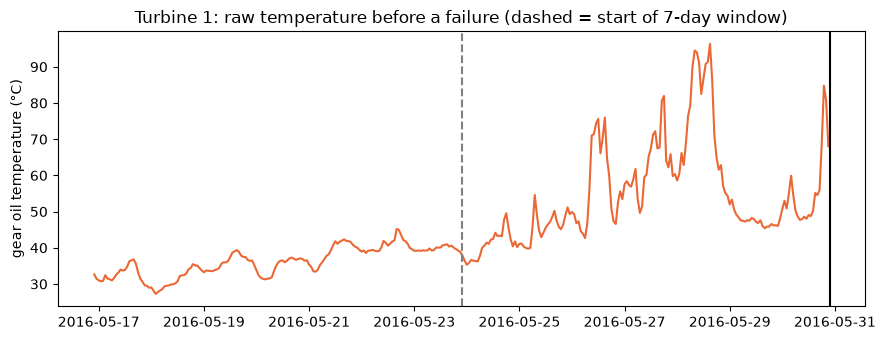

In [13]:
f = kel_failures[kel_failures.message.str.contains("Gearbox")].iloc[0]
w = kel[(kel.turbine == f.turbine) & (kel["Date and time"] > f.t_fail - pd.Timedelta(days=14)) & (kel["Date and time"] <= f.t_fail)]
plt.figure(figsize=(9, 3.5))
plt.plot(w["Date and time"], w["Gear oil temperature (°C)"], color="#eb6834")
plt.axvline(f.t_fail, color="k"); plt.axvline(f.t_fail - pd.Timedelta(days=PRE_DAYS), color="grey", ls="--")
plt.ylabel("gear oil temperature (°C)"); plt.title(f"Turbine {f.turbine}: raw temperature before a failure (dashed = start of 7-day window)")
plt.tight_layout(); plt.show()

Before this gearbox failure (solid line) the oil temperature stays near 30-40 °C, then **climbs to more than 90 °C** after the dashed line that marks the start of the 7-day window. The raw signal is noisy, because temperature also changes with wind and power.

## 4. Feature Engineering: How Far Is Each Sensor from Normal?
A gearbox can run hot just because it is windy. So we first learn what each sensor *should* read for the current wind, power, rotor speed and outside temperature (a **normal-behaviour model**), then use the **difference** (actual minus expected) as the signal. A rising difference means something is changing inside the machine.

### 4.1 Normal-behaviour model

In [14]:
from sklearn.ensemble import HistGradientBoostingRegressor

kel["power_mean_6h"] = kel.groupby("turbine")["Power (kW)"].transform(lambda s: s.rolling(6, min_periods=3).mean())
DRIVER_COLS = DRIVERS + ["power_mean_6h"]                 # inputs of the normal-behaviour model

def fit_normal_model(df, sensors):
    """One small model per sensor, trained on normal hours only."""
    df = df.dropna(subset=DRIVER_COLS)
    df = df.sample(min(len(df), 100_000), random_state=0)
    models = {}
    for s in sensors:
        rows = df.dropna(subset=[s])
        models[s] = HistGradientBoostingRegressor(max_iter=100, max_depth=6, random_state=0).fit(rows[DRIVER_COLS], rows[s])
    return models

is_train = kel["Date and time"].dt.year.isin(TRAIN_YEARS)
healthy_train = kel[is_train & (kel.label == 0) & ~kel.skip]
normal_model = fit_normal_model(healthy_train, SENSORS)
print("Trained", len(normal_model), "normal-behaviour models on", f"{len(healthy_train):,}", "normal training hours")

Trained 12 normal-behaviour models on 247,879 normal training hours


**12 normal-behaviour models** were trained, one per sensor, using normal training hours only (247,879 hours; pre-failure hours and stops are left out). Each model predicts what its sensor should read given wind, power, rotor speed and outside temperature.

### 4.2 Residuals (actual minus expected)
Each turbine gets its own small correction so that turbine-to-turbine offsets do not count as problems.

In [15]:
def get_residuals(df, models, sensors):
    res = pd.DataFrame(index=df.index, columns=sensors, dtype="float64")
    ok = df[DRIVER_COLS].notna().all(axis=1)
    for s in sensors:
        res.loc[ok, s] = df.loc[ok, s] - models[s].predict(df.loc[ok, DRIVER_COLS])
    res[df["skip"]] = np.nan                                  # ignore stopped hours
    return res

kel_res = get_residuals(kel, normal_model, SENSORS)
offset = kel_res[is_train & (kel.label == 0)].groupby(kel.turbine).median()      # each turbine's own normal offset
kel_res = kel_res - offset.reindex(kel.turbine).to_numpy()
kel_res.describe().loc[["mean", "std"]].round(2).T.rename(columns={"mean": "mean residual", "std": "std residual"})

,mean residual,std residual
Gear oil temperature (°C),0.22,2.02
Front bearing temperature (°C),0.04,1.17
Generator bearing front temperature (°C),0.15,1.60
Generator bearing rear temperature (°C),0.07,1.15
Stator temperature 1 (°C),0.12,1.73
Transformer temperature (°C),0.10,1.96
Nacelle temperature (°C),0.00,0.45
Gear oil inlet pressure (bar),-0.01,0.08
Hydraulic oil pressure (bar),-0.21,3.94
Tower Acceleration X (mm/ss),0.37,4.79


On normal hours the residuals (actual minus expected) are centred **close to 0** with small spreads, for example about ±2 °C for gear oil and ±1.2 °C for the front bearing. So a large residual is unusual and worth attention.

### 4.3 The same failure, as residuals
The residual stays near 0 while the machine is healthy and rises towards the failure, much clearer than the raw temperature above.

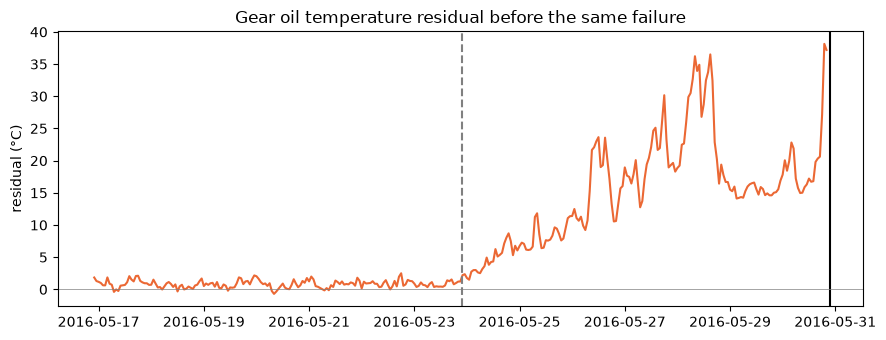

In [16]:
w_idx = w.index
plt.figure(figsize=(9, 3.5))
plt.plot(kel.loc[w_idx, "Date and time"], kel_res.loc[w_idx, "Gear oil temperature (°C)"], color="#eb6834")
plt.axvline(f.t_fail, color="k"); plt.axvline(f.t_fail - pd.Timedelta(days=PRE_DAYS), color="grey", ls="--"); plt.axhline(0, color="grey", lw=0.5)
plt.ylabel("residual (°C)"); plt.title("Gear oil temperature residual before the same failure"); plt.tight_layout(); plt.show()

The same failure as residuals: the gear oil residual is **flat near 0 until the dashed line, then rises to over 35 °C**. Removing the effect of wind and power makes the drift much clearer than in the raw temperature plot above.

### 4.4 Build the feature table
For every sensor: the residual now, its average over the last 6 hours, and over the last 24 hours (short averages remove noise).

In [17]:
def make_features(res, df):
    feats = {}
    for s in res.columns:
        feats[f"{s}__now"] = res[s]
        feats[f"{s}__6h"] = res[s].groupby(df["turbine"]).transform(lambda x: x.rolling(6, min_periods=3).mean())
        feats[f"{s}__24h"] = res[s].groupby(df["turbine"]).transform(lambda x: x.rolling(24, min_periods=12).mean())
    feats["power_pct"] = df["Power (kW)"] / 2050 * 100        # how loaded the turbine is
    return pd.DataFrame(feats).fillna(0)                      # missing = no deviation from normal

X = make_features(kel_res, kel)
print("Feature table:", X.shape[0], "rows x", X.shape[1], "features")
X.iloc[:, :6].describe().round(2)

Feature table: 368208 rows x 37 features


,Gear oil temperature (°C)__now,Gear oil temperature (°C)__6h,Gear oil temperature (°C)__24h,Front bearing temperature (°C)__now,Front bearing temperature (°C)__6h,Front bearing temperature (°C)__24h
count,368208.00,368208.00,368208.00,368208.00,368208.00,368208.00
mean,0.21,0.22,0.22,0.04,0.04,0.04
std,1.98,1.70,1.60,1.15,0.82,0.71
min,-10.26,-6.39,-2.60,-10.25,-5.29,-2.11
25%,-0.69,-0.48,-0.39,-0.59,-0.33,-0.19
50%,0.01,0.01,0.00,0.00,0.00,-0.00
75%,0.91,0.66,0.56,0.62,0.33,0.18
max,52.95,51.08,44.59,38.53,37.80,35.74


Each of the 12 sensors gives three features (residual now, 6-hour average, 24-hour average), plus power as context, so there are **37 features for 368,208 hours**. The summary shows that the residual features are centred near 0, with a few large values in the max column, which are the fault hours.

### 4.5 Split by year and scale
Train = 2016-2020, validation = 2021 (to choose thresholds), test = 2022 (final report, never used for tuning). Scaling uses normal training hours only.

In [18]:
from sklearn.preprocessing import StandardScaler

year = kel["Date and time"].dt.year
use = ~kel.skip
tr, va, te = (use & year.isin(TRAIN_YEARS)).to_numpy(), (use & (year == VAL_YEAR)).to_numpy(), (use & (year == TEST_YEAR)).to_numpy()

scaler = StandardScaler().fit(X[tr & (kel.label == 0).to_numpy()])
Z = np.clip(scaler.transform(X), -8, 8)
y = kel["label"].to_numpy()
meta = kel[["turbine", "Date and time", "label", "episode", "days_to_failure"]]
Z_tr, y_tr, Z_va, y_va, Z_te, y_te = Z[tr], y[tr], Z[va], y[va], Z[te], y[te]

pd.DataFrame({"hours": [tr.sum(), va.sum(), te.sum()], "pre-failure hours": [y_tr.sum(), y_va.sum(), y_te.sum()],
              "pre-failure %": [round(y_tr.mean() * 100, 1), round(y_va.mean() * 100, 1), round(y_te.mean() * 100, 1)]},
             index=["train (2016-2020)", "validation (2021)", "test (2022)"])

,hours,pre-failure hours,pre-failure %
train (2016-2020),257345,9466,3.7
validation (2021),51246,2480,4.8
test (2022),50980,2153,4.2


The split is by year, which avoids leakage between sets. **Train** (2016-2020) has 257,345 hours (3.7 % pre-failure), **validation** (2021) has 51,246 (4.8 %) and **test** (2022) has 50,980 (4.2 %). The test year is never used for choosing anything.

### 4.6 PCA and Kernel PCA (2-D view of the features)
If failures separate from normal hours in this picture, the features carry a real signal.

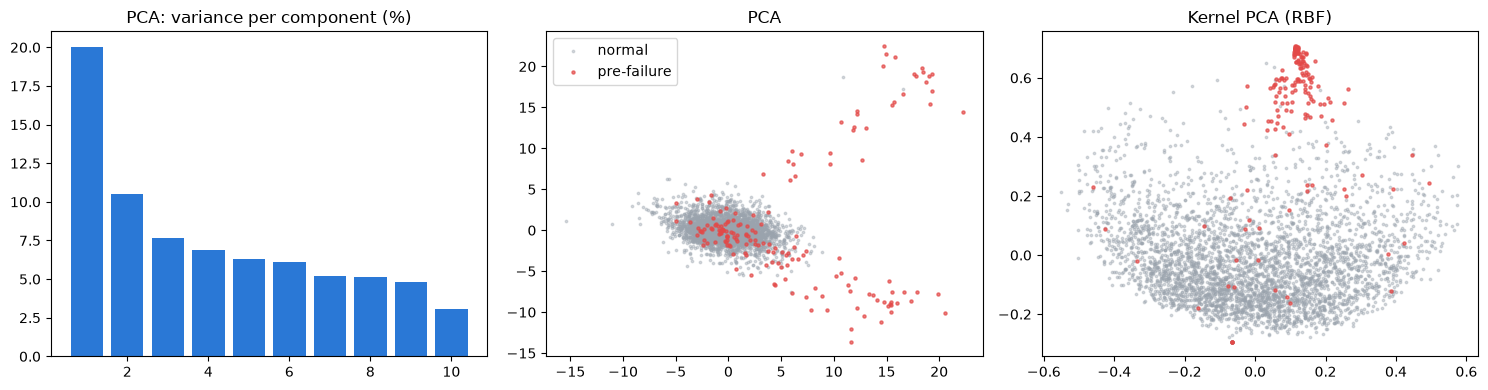

In [19]:
from sklearn.decomposition import PCA, KernelPCA

pick = np.random.RandomState(0).choice(len(Z_tr), 4000, replace=False)
pca = PCA(n_components=10).fit(Z_tr[pick])
p2 = pca.transform(Z_tr[pick])[:, :2]
k2 = KernelPCA(n_components=2, kernel="rbf", gamma=0.01).fit_transform(Z_tr[pick])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].bar(range(1, 11), pca.explained_variance_ratio_ * 100, color="#2a78d6"); ax[0].set_title("PCA: variance per component (%)")
for a, pts, name in [(ax[1], p2, "PCA"), (ax[2], k2, "Kernel PCA (RBF)")]:
    a.scatter(pts[y_tr[pick] == 0, 0], pts[y_tr[pick] == 0, 1], s=3, alpha=0.4, label="normal", color="#9aa3ad")
    a.scatter(pts[y_tr[pick] == 1, 0], pts[y_tr[pick] == 1, 1], s=5, alpha=0.7, label="pre-failure", color="#e34948"); a.set_title(name)
ax[1].legend(); plt.tight_layout(); plt.show()

The first PCA component explains about 20 % of the variance. In the 2-D views most pre-failure hours (red) overlap with normal ones, but a group stretches away from the main cloud, and Kernel PCA (right) pulls a cluster of them to the top. Failures are therefore partly separable, with some hard cases remaining.

## 5. Model Development and Training
### 5.1 Evaluation helpers
* We pick each model's **alert threshold on the validation year (2021)**: the score that gives the best F1.
* Then we measure the **test year (2022)** with that fixed threshold.
* **Precision** = of the hours we flag, how many are truly pre-failure. **Recall** = of the truly pre-failure hours, how many we flag.
* **Accuracy** = share of all hours classified correctly. It looks high for every model because about 96 % of hours are normal, so judge the models mainly by precision, recall, F1 and PR-AUC.


In [20]:
from sklearn.metrics import (precision_recall_curve, average_precision_score, roc_auc_score, precision_score, recall_score, f1_score, accuracy_score)

results, scores, thresholds = [], {}, {}

def best_threshold(y_true, score):
    prec, rec, thr = precision_recall_curve(y_true, score)
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
    return thr[np.argmax(f1)]

def evaluate(name, score_va, score_te):
    thr = best_threshold(y_va, score_va)
    alert = score_te >= thr
    row = dict(model=name, accuracy=accuracy_score(y_te, alert), precision=precision_score(y_te, alert), recall=recall_score(y_te, alert), f1=f1_score(y_te, alert),
               pr_auc=average_precision_score(y_te, score_te), roc_auc=roc_auc_score(y_te, score_te))
    results.append(row); scores[name] = (score_va, score_te); thresholds[name] = thr
    return pd.DataFrame([row]).set_index("model").round(3)

### 5.2 Logistic Regression
A straight-line model: each feature gets a weight. Simple and fast.

In [21]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(class_weight="balanced", max_iter=300).fit(Z_tr, y_tr)
evaluate("Logistic Regression", lr.predict_proba(Z_va)[:, 1], lr.predict_proba(Z_te)[:, 1])

,accuracy,precision,recall,f1,pr_auc,roc_auc
model,,,,,,
Logistic Regression,0.983,0.854,0.709,0.775,0.688,0.934


**Logistic Regression** on the 2022 test year: accuracy 0.98, precision 0.85, recall 0.71, PR-AUC 0.69. A simple straight-line model already beats the no-skill PR-AUC of about 0.04 by a wide margin.

### 5.3 Support Vector Machine (linear)
Finds the line that best separates pre-failure from normal hours.

In [22]:
from sklearn.linear_model import SGDClassifier
svm = SGDClassifier(loss="hinge", class_weight="balanced", random_state=0).fit(Z_tr, y_tr)
evaluate("SVM (linear)", svm.decision_function(Z_va), svm.decision_function(Z_te))

,accuracy,precision,recall,f1,pr_auc,roc_auc
model,,,,,,
SVM (linear),0.98,0.78,0.728,0.753,0.693,0.935


**Linear SVM:** accuracy 0.98, precision 0.78, recall 0.73, PR-AUC 0.69, so it lands in the same range as Logistic Regression, as expected for two linear models.

### 5.4 Gaussian Naive Bayes
Assumes each feature is bell-shaped within each class and combines them with Bayes' rule.

In [23]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB().fit(Z_tr, y_tr)
evaluate("Naive Bayes", nb.predict_proba(Z_va)[:, 1], nb.predict_proba(Z_te)[:, 1])

,accuracy,precision,recall,f1,pr_auc,roc_auc
model,,,,,,
Naive Bayes,0.981,0.778,0.758,0.768,0.697,0.916


**Naive Bayes:** precision 0.78, recall 0.76, PR-AUC 0.70. Its independence assumption fits poorly because the features are correlated, but it still performs reasonably.

### 5.5 Random Forest
Many decision trees voting together; handles non-linear patterns.

In [24]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=5, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=0).fit(Z_tr, y_tr)
evaluate("Random Forest", rf.predict_proba(Z_va)[:, 1], rf.predict_proba(Z_te)[:, 1])

,accuracy,precision,recall,f1,pr_auc,roc_auc
model,,,,,,
Random Forest,0.987,0.871,0.809,0.839,0.807,0.953


**Random Forest** gives the best PR-AUC (0.81) with precision 0.87, recall 0.81 and F1 0.84. It handles the non-linear patterns better than the linear models.

### 5.6 Gradient Boosting
Trees built one after another, each fixing the mistakes of the previous ones.

In [25]:
from sklearn.ensemble import HistGradientBoostingClassifier
gb = HistGradientBoostingClassifier(max_iter=200, max_depth=4, learning_rate=0.1, class_weight="balanced", random_state=0).fit(Z_tr, y_tr)
evaluate("Gradient Boosting", gb.predict_proba(Z_va)[:, 1], gb.predict_proba(Z_te)[:, 1])

,accuracy,precision,recall,f1,pr_auc,roc_auc
model,,,,,,
Gradient Boosting,0.985,0.859,0.771,0.813,0.76,0.949


**Gradient Boosting** is a little behind Random Forest (PR-AUC 0.76, precision 0.86, recall 0.77).

### 5.7 Neural network (ANN)
Two hidden layers (64 and 32 neurons). Normal hours are down-sampled to 3 per failure hour because the network has no class-weight option.

In [26]:
from sklearn.neural_network import MLPClassifier
rng = np.random.RandomState(0)
pos, neg = np.flatnonzero(y_tr == 1), np.flatnonzero(y_tr == 0)
keep = np.concatenate([pos, rng.choice(neg, 3 * len(pos), replace=False)])
ann = MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=200, random_state=0).fit(Z_tr[keep], y_tr[keep])
evaluate("ANN (64-32)", ann.predict_proba(Z_va)[:, 1], ann.predict_proba(Z_te)[:, 1])

,accuracy,precision,recall,f1,pr_auc,roc_auc
model,,,,,,
ANN (64-32),0.983,0.82,0.771,0.795,0.735,0.943


**ANN (64-32):** PR-AUC 0.74 and F1 0.80, in the same range as the other supervised models, a little below the tree models.

### 5.8 Isolation Forest (unsupervised)
Never sees the labels: it only learns what normal looks like and scores how unusual each hour is.

In [27]:
from sklearn.ensemble import IsolationForest
iso = IsolationForest(n_estimators=150, random_state=0, n_jobs=-1).fit(Z_tr[y_tr == 0])
evaluate("Isolation Forest", -iso.score_samples(Z_va), -iso.score_samples(Z_te))

,accuracy,precision,recall,f1,pr_auc,roc_auc
model,,,,,,
Isolation Forest,0.933,0.302,0.44,0.358,0.375,0.816


**Isolation Forest** never sees the labels and is clearly the weakest (PR-AUC 0.38, precision 0.30, accuracy 0.93). It still reaches ROC-AUC 0.82, so unusual sensor behaviour carries some signal, but it flags many normal hours too.

### 5.9 Fused risk score
Average of the Logistic Regression, Random Forest and Gradient Boosting probabilities. Averaging models usually makes the alert steadier.

In [28]:
fuse = lambda i: np.mean([scores[m][i] for m in ["Logistic Regression", "Random Forest", "Gradient Boosting"]], axis=0)
evaluate("Fused risk score", fuse(0), fuse(1))

,accuracy,precision,recall,f1,pr_auc,roc_auc
model,,,,,,
Fused risk score,0.987,0.873,0.819,0.845,0.786,0.959


The **fused risk score** (average of Logistic Regression, Random Forest and Gradient Boosting) has the best ROC-AUC (0.96) and F1 (0.845), and balances precision (0.87) and recall (0.82).

## 6. Model Evaluation and Validation
### 6.1 All models side by side (test year 2022)

In [29]:
comparison = pd.DataFrame(results).set_index("model").sort_values("pr_auc", ascending=False).round(3)
comparison.to_csv(f"{OUT}/model_comparison_test.csv")
print(f"No-skill level: PR-AUC is about {y_te.mean():.3f} (the share of pre-failure hours in the test year)")
print(f"Accuracy baseline: always answering \"normal\" already gives accuracy {1 - y_te.mean():.3f}, so read accuracy together with precision and recall")
comparison

No-skill level: PR-AUC is about 0.042 (the share of pre-failure hours in the test year)
Accuracy baseline: always answering "normal" already gives accuracy 0.958, so read accuracy together with precision and recall


,accuracy,precision,recall,f1,pr_auc,roc_auc
model,,,,,,
Random Forest,0.987,0.871,0.809,0.839,0.807,0.953
Fused risk score,0.987,0.873,0.819,0.845,0.786,0.959
Gradient Boosting,0.985,0.859,0.771,0.813,0.760,0.949
ANN (64-32),0.983,0.820,0.771,0.795,0.735,0.943
Naive Bayes,0.981,0.778,0.758,0.768,0.697,0.916
SVM (linear),0.980,0.780,0.728,0.753,0.693,0.935
Logistic Regression,0.983,0.854,0.709,0.775,0.688,0.934
Isolation Forest,0.933,0.302,0.440,0.358,0.375,0.816


All models side by side, sorted by PR-AUC. The no-skill level is about **0.04**, so every model is far above chance. Random Forest has the best PR-AUC (0.81) and the fused score the best F1 (0.845) and ROC-AUC (0.96). **Accuracy is 0.98-0.99 for every supervised model and the "always normal" baseline already scores 0.958**, so accuracy hardly separates the models; precision, recall and PR-AUC do. Isolation Forest is last. These scores are very high for failure prediction, so read them together with the data note at the top and the limitations section at the end.

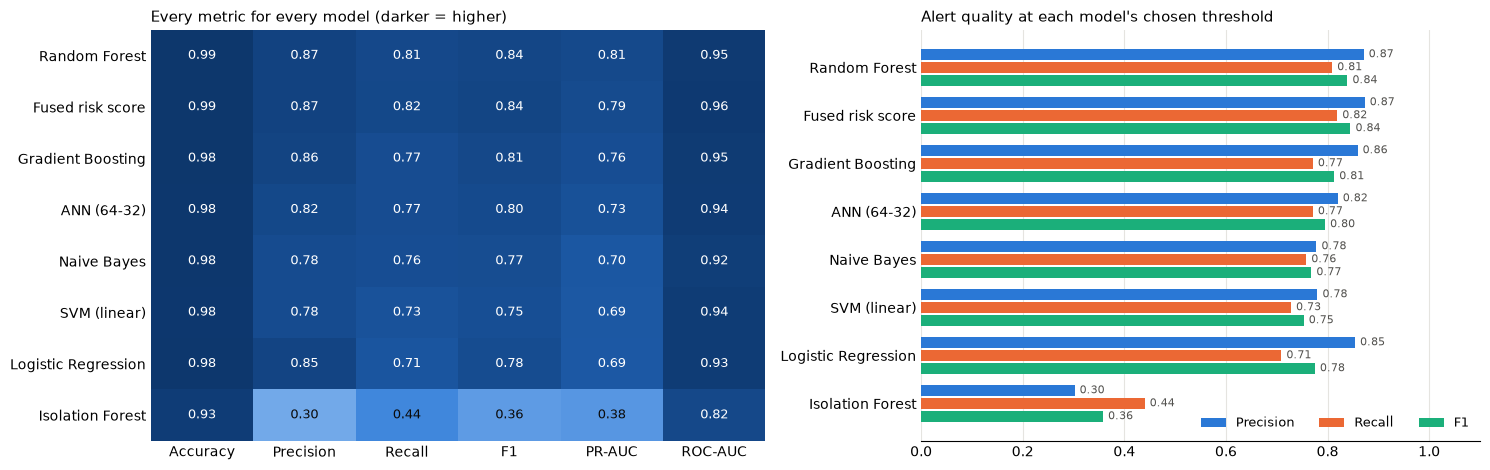

In [30]:
from matplotlib.colors import LinearSegmentedColormap

metrics = ["accuracy", "precision", "recall", "f1", "pr_auc", "roc_auc"]
metric_names = ["Accuracy", "Precision", "Recall", "F1", "PR-AUC", "ROC-AUC"]
blue = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])   # one hue, light = low, dark = high
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e5e4e0"

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})

# left: heatmap of every metric for every model
vals = comparison[metrics].to_numpy()
ax1.imshow(vals, cmap=blue, vmin=0, vmax=1, aspect="auto")
ax1.set_xticks(range(len(metrics)), metric_names)
ax1.set_yticks(range(len(comparison)), comparison.index)
for r in range(vals.shape[0]):
    for c in range(vals.shape[1]):
        ax1.text(c, r, f"{vals[r, c]:.2f}", ha="center", va="center", fontsize=9, color="white" if vals[r, c] >= 0.55 else INK)
ax1.set_title("Every metric for every model (darker = higher)", loc="left", fontsize=11)
ax1.tick_params(length=0)
for side in ax1.spines.values():
    side.set_visible(False)

# right: precision, recall and F1 side by side (the three metrics that depend on the chosen alert threshold)
colours = {"precision": "#2a78d6", "recall": "#eb6834", "f1": "#1baf7a"}
labels = {"precision": "Precision", "recall": "Recall", "f1": "F1"}
height, gap = 0.24, 0.03
rows = np.arange(len(comparison))
for k, (m, colour) in enumerate(colours.items()):
    y_pos = rows + (k - 1) * (height + gap)
    ax2.barh(y_pos, comparison[m], height=height, color=colour, label=labels[m])
    for yy, v in zip(y_pos, comparison[m]):
        ax2.text(v + 0.01, yy, f"{v:.2f}", va="center", fontsize=8, color=MUTED)
ax2.set_yticks(rows, comparison.index)
ax2.invert_yaxis()
ax2.set_xlim(0, 1.1)
ax2.set_title("Alert quality at each model's chosen threshold", loc="left", fontsize=11)
ax2.grid(axis="x", color=GRID, linewidth=0.8)
ax2.set_axisbelow(True)
ax2.legend(frameon=False, ncol=3, loc="lower right", fontsize=9)
ax2.tick_params(length=0)
for side in ["top", "right", "left"]:
    ax2.spines[side].set_visible(False)

plt.tight_layout()
plt.show()


The heatmap shows every metric for every model at once (darker = higher). **Accuracy is almost the same for all supervised models (0.98-0.99)**, because about 96 % of hours are normal, so the differences show up in the other columns. In the bars, Random Forest and the fused score are the best on both precision (0.87) and recall (0.81-0.82), Logistic Regression and the SVM trade recall (0.71-0.73) for precision, and Isolation Forest is far behind on every metric.

### 6.2 Precision-recall and ROC curves

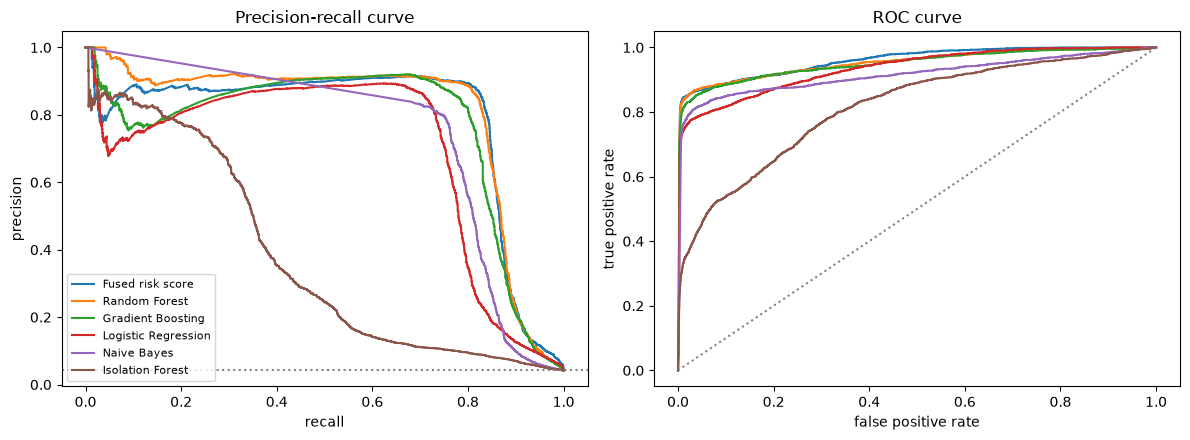

In [31]:
from sklearn.metrics import roc_curve
show = ["Fused risk score", "Random Forest", "Gradient Boosting", "Logistic Regression", "Naive Bayes", "Isolation Forest"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name in show:
    p, r, _ = precision_recall_curve(y_te, scores[name][1]); ax[0].plot(r, p, label=name)
    fpr, tpr, _ = roc_curve(y_te, scores[name][1]); ax[1].plot(fpr, tpr, label=name)
ax[0].axhline(y_te.mean(), color="grey", ls=":"); ax[0].set(xlabel="recall", ylabel="precision", title="Precision-recall curve")
ax[1].plot([0, 1], [0, 1], color="grey", ls=":"); ax[1].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curve")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

The precision-recall curves (left) stay around 0.9 precision until recall reaches about 0.8 and then fall off; the dotted line marks the no-skill level. The ROC curves (right) of the supervised models hug the top-left corner. Isolation Forest (brown) is clearly lower in both plots.

### 6.3 Confusion matrix of the best model
Rows = what really happened, columns = what the model said.

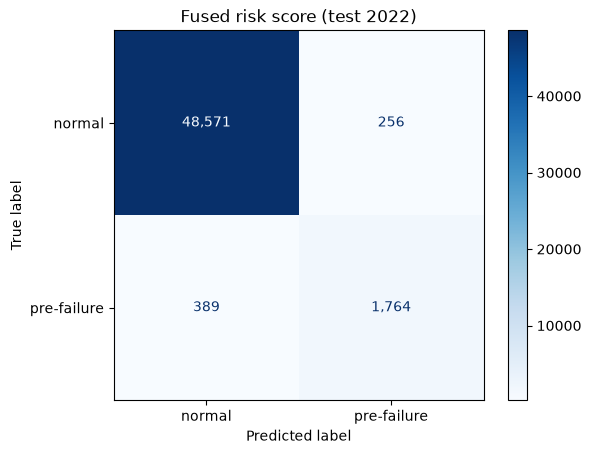

In [32]:
from sklearn.metrics import ConfusionMatrixDisplay
best = comparison.drop(index=["Isolation Forest"]).f1.idxmax()
alert_best = scores[best][1] >= thresholds[best]
ConfusionMatrixDisplay.from_predictions(y_te, alert_best, display_labels=["normal", "pre-failure"], cmap="Blues", values_format=",d")
plt.title(f"{best} (test 2022)"); plt.show()

On the 2022 test year the fused model **correctly flags 1,764 of 2,153 pre-failure hours**, misses 389 and raises 256 false alarms among 48,827 normal hours.

### 6.4 Which sensors matter most?
Random Forest importance, added up per sensor.

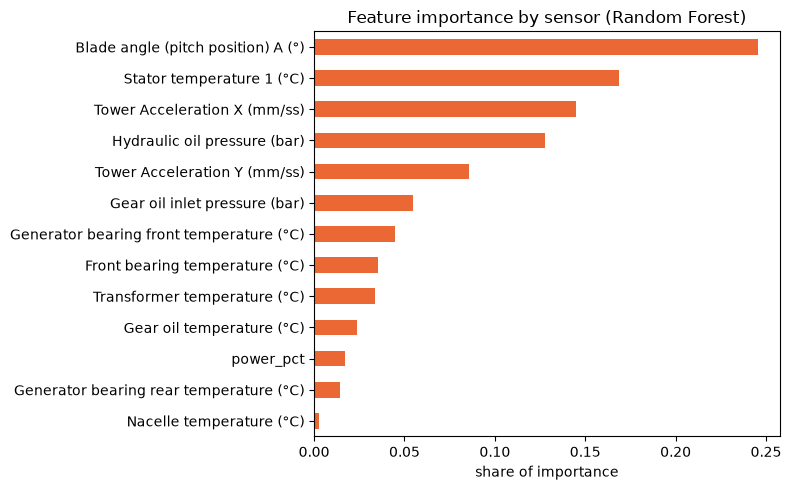

In [33]:
importance = pd.Series(rf.feature_importances_, index=X.columns)
by_sensor = importance.groupby([c.split("__")[0] for c in X.columns]).sum().sort_values()
by_sensor.plot.barh(figsize=(8, 5), color="#eb6834")
plt.xlabel("share of importance"); plt.title("Feature importance by sensor (Random Forest)"); plt.tight_layout(); plt.show()

The most important sensor groups for Random Forest are **blade angle (pitch), stator temperature, tower vibration (X) and hydraulic oil pressure**. Importance is shared among correlated sensors, so section 9.6 checks it again with permutation importance.

### 6.5 Failure-level view: did we warn before each failure?
Row-level scores treat every hour alone. In practice we care whether a **failure got a warning** in time, and how many **false alarms** we raise.

In [34]:
def failure_level(name):
    alert = scores[name][1] >= thresholds[name]
    m = meta[te].reset_index(drop=True)
    caught, lead = [], []
    for ep, rows in m[m.label == 1].groupby("episode"):
        hit = alert[rows.index.to_numpy()]
        caught.append(hit.any())
        if hit.any():
            lead.append(rows["days_to_failure"].to_numpy()[hit].max())          # warning time before the failure
    normal = m[(m.label == 0)].assign(alert=alert[m.label == 0]).query("alert").sort_values(["turbine", "Date and time"])
    new_event = normal.groupby("turbine")["Date and time"].diff().isna() | (normal.groupby("turbine")["Date and time"].diff() > pd.Timedelta(hours=24))
    return dict(model=name, failures=len(caught), warned=int(sum(caught)), warned_pct=round(100 * np.mean(caught)),
                median_warning_days=round(float(np.median(lead)), 1), false_alarms_per_turbine_year=round(new_event.sum() / m.turbine.nunique(), 1))

pd.DataFrame([failure_level(n) for n in ["Fused risk score", "Random Forest", "Gradient Boosting", "Logistic Regression"]]).set_index("model")

,failures,warned,warned_pct,median_warning_days,false_alarms_per_turbine_year
model,,,,,
Fused risk score,13,13,100,6.5,5.0
Random Forest,13,13,100,6.3,6.0
Gradient Boosting,13,13,100,6.5,5.8
Logistic Regression,13,12,92,6.4,5.5


Counted per failure instead of per hour, the Random Forest, Gradient Boosting and fused models **warn before all 13 failures in 2022**, and Logistic Regression before 12. The median warning comes about **6.3-6.5 days** ahead, at the cost of roughly **5-6 false alarms per turbine per year**.

### 6.6 Confidence intervals (bootstrap)
The test year has few failures, so one number can be lucky. We re-draw the test set many times (in blocks of one turbine-week, because neighbouring hours are almost identical) and look at the spread.

In [35]:
def bootstrap_ci(name, n_boot=300):
    alert = scores[name][1] >= thresholds[name]
    m = meta[te].reset_index(drop=True)
    block = m.turbine.astype(str) + "_" + m["Date and time"].dt.isocalendar().week.astype(str)
    counts = pd.DataFrame({"tp": alert & (y_te == 1), "fp": alert & (y_te == 0), "fn": ~alert & (y_te == 1)}).groupby(block.to_numpy()).sum()
    rng, out = np.random.RandomState(0), []
    for _ in range(n_boot):
        c = counts.iloc[rng.randint(0, len(counts), len(counts))].sum()
        p, r = c.tp / max(c.tp + c.fp, 1), c.tp / max(c.tp + c.fn, 1)
        out.append((p, r, 2 * p * r / max(p + r, 1e-9)))
    lo, hi = np.percentile(out, 2.5, axis=0), np.percentile(out, 97.5, axis=0)
    return {"model": name, **{k: f"[{l:.2f} - {h:.2f}]" for k, l, h in zip(["precision 95% CI", "recall 95% CI", "F1 95% CI"], lo, hi)}}

pd.DataFrame([bootstrap_ci(n) for n in ["Fused risk score", "Random Forest", "Gradient Boosting", "Logistic Regression"]]).set_index("model")

,precision 95% CI,recall 95% CI,F1 95% CI
model,,,
Fused risk score,[0.72 - 0.97],[0.70 - 0.92],[0.73 - 0.92]
Random Forest,[0.72 - 0.97],[0.68 - 0.91],[0.73 - 0.91]
Gradient Boosting,[0.70 - 0.96],[0.62 - 0.88],[0.71 - 0.89]
Logistic Regression,[0.69 - 0.95],[0.55 - 0.84],[0.66 - 0.87]


The 95 % confidence intervals are wide because the test year has only 13 failures. For the fused score, precision is 0.72-0.97 and recall 0.70-0.92, so small differences between the top models are not meaningful.

### 6.7 Stratified cross-validation (training years)
5 folds. Hours from the same 2-week block always stay in the same fold, so a failure cannot leak between training and checking.

In [36]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.base import clone

groups = (meta[tr].turbine.astype(str) + "_" + (meta[tr]["Date and time"].dt.dayofyear // 14).astype(str) + "_" + meta[tr]["Date and time"].dt.year.astype(str)).to_numpy()
cv_rows = []
for name, model in [("Logistic Regression", lr), ("Naive Bayes", nb), ("Random Forest", rf), ("Gradient Boosting", gb)]:
    aps, aucs = [], []
    for fit_idx, chk_idx in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(Z_tr, y_tr, groups):
        m = clone(model)
        if name == "Random Forest": m.set_params(n_estimators=50, max_depth=10)       # smaller forest only inside the CV loop, to keep it fast
        m.fit(Z_tr[fit_idx], y_tr[fit_idx]); p = m.predict_proba(Z_tr[chk_idx])[:, 1]
        aps.append(average_precision_score(y_tr[chk_idx], p)); aucs.append(roc_auc_score(y_tr[chk_idx], p))
    cv_rows.append({"model": name, "PR-AUC mean": np.mean(aps), "PR-AUC std": np.std(aps), "ROC-AUC mean": np.mean(aucs), "ROC-AUC std": np.std(aucs)})
pd.DataFrame(cv_rows).set_index("model").round(3)

,PR-AUC mean,PR-AUC std,ROC-AUC mean,ROC-AUC std
model,,,,
Logistic Regression,0.665,0.081,0.861,0.043
Naive Bayes,0.751,0.045,0.929,0.028
Random Forest,0.826,0.054,0.944,0.029
Gradient Boosting,0.815,0.049,0.926,0.030


Five-fold cross-validation on the training years gives a similar ranking: Random Forest (PR-AUC 0.83 ± 0.05) and Gradient Boosting (0.82 ± 0.05) are best, then Naive Bayes (0.75) and Logistic Regression (0.67). The scores are consistent with the test-year results.

## 7. Remaining Useful Life and Cross-Farm Generalisation
### 7.1 Remaining useful life (RUL): how many days until the failure?
We train only on pre-failure hours and predict `days_to_failure` (0 to 7). We compare Linear, Ridge and Lasso regression with a baseline that always guesses the average.

In [37]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, r2_score

pre_tr, pre_te = tr & (y == 1), te & (y == 1)
days = kel["days_to_failure"].to_numpy()
rul_models = {}
rul_rows = [{"model": "Always guess the average", "MAE (days)": mean_absolute_error(days[pre_te], np.full(pre_te.sum(), days[pre_tr].mean())), "R2": 0.0}]
for name, reg in [("Linear", LinearRegression()), ("Ridge", Ridge(alpha=100)), ("Lasso", Lasso(alpha=0.01))]:
    reg.fit(Z[pre_tr], days[pre_tr]); pred = np.clip(reg.predict(Z[pre_te]), 0, PRE_DAYS)
    rul_models[name] = reg
    rul_rows.append({"model": name, "MAE (days)": mean_absolute_error(days[pre_te], pred), "R2": r2_score(days[pre_te], pred)})
rul = pd.DataFrame(rul_rows).set_index("model").round(2); rul.to_csv(f"{OUT}/rul_results.csv"); rul

,MAE (days),R2
model,,
Always guess the average,1.75,0.00
Linear,1.51,0.22
Ridge,1.51,0.22
Lasso,1.52,0.21


Predicting the days until failure is much harder: Linear, Ridge and Lasso reach a mean error of **about 1.5 days** (R² about 0.2) against 1.75 days for always guessing the average. Detecting a failure is much easier than timing it.

### 7.2 Cross-farm test: train on Kelmarsh, test on Penmanshiel (no retraining)
A model is only useful if it works on a farm it has never seen. Rules: use only sensors both farms have, and do not tune anything on Penmanshiel (the alert threshold comes from Kelmarsh 2021).

In [38]:
pen, pen_status = load_farm("Penmanshiel")
pen_failures = find_failures(pen_status)
pen = add_labels(pen, pen_failures, pen_status)
pen["power_mean_6h"] = pen.groupby("turbine")["Power (kW)"].transform(lambda s: s.rolling(6, min_periods=3).mean())
common = [s for s in SENSORS if s in pen.columns and pen[s].notna().any()]
print(f"Penmanshiel: {len(pen_failures)} failures, {pen.turbine.nunique()} turbines. Sensors in both farms: {len(common)} of {len(SENSORS)}")
print("Missing in Penmanshiel:", [s for s in SENSORS if s not in common])

Penmanshiel: 128 failures, 14 turbines. Sensors in both farms: 10 of 12
Missing in Penmanshiel: ['Gear oil inlet pressure (bar)', 'Hydraulic oil pressure (bar)']


Penmanshiel loaded with **128 failures across 14 turbines**. Only 10 of the 12 sensors exist in both farms (gear oil inlet pressure and hydraulic oil pressure are missing in Penmanshiel), so the cross-farm test uses the common sensors only.

Penmanshiel residuals use the **Kelmarsh** normal-behaviour models; each turbine's offset comes from its own first 25 % of time.

In [39]:
pen_res = get_residuals(pen, normal_model, common)
first_quarter = pen.groupby("turbine")["Date and time"].transform(lambda t: t < t.min() + 0.25 * (t.max() - t.min()))
pen_res = pen_res - pen_res[first_quarter & (pen.label == 0)].groupby(pen.turbine).median().reindex(pen.turbine).to_numpy()
Xp = make_features(pen_res, pen)
cols = [c for c in X.columns if c.split("__")[0] in common or c == "power_pct"]
print("Common features:", len(cols))

Common features: 31


The Kelmarsh normal-behaviour models were applied to Penmanshiel, which gives **31 common features** (10 sensors × 3, plus power) for the cross-farm test.

Compare two ways of scaling the Penmanshiel features: with Kelmarsh statistics, or with its own first 25 % of data (no labels needed).

In [40]:
idx = [list(X.columns).index(c) for c in cols]
gb_common = HistGradientBoostingClassifier(max_iter=200, max_depth=4, learning_rate=0.1, class_weight="balanced", random_state=0).fit(Z_tr[:, idx], y_tr)
thr = best_threshold(y_va, gb_common.predict_proba(Z_va[:, idx])[:, 1])

use_p = ~pen.skip.to_numpy(); y_p = pen.label.to_numpy()[use_p]
own = first_quarter.to_numpy() & use_p & (pen.label == 0).to_numpy()
mean_own, std_own = Xp.loc[own, cols].mean().to_numpy(), Xp.loc[own, cols].std().to_numpy() + 1e-6
versions = {"Penmanshiel, scaled with its own data": (Xp[cols].to_numpy() - mean_own) / std_own,
            "Penmanshiel, scaled with Kelmarsh data": (Xp[cols].to_numpy() - scaler.mean_[idx]) / scaler.scale_[idx]}
rows = []
p_k = gb_common.predict_proba(Z_te[:, idx])[:, 1]
rows.append(dict(data="Kelmarsh test 2022 (same farm)", pr_auc=average_precision_score(y_te, p_k), roc_auc=roc_auc_score(y_te, p_k),
                 precision=precision_score(y_te, p_k >= thr), recall=recall_score(y_te, p_k >= thr)))
for name, Zp in versions.items():
    p = gb_common.predict_proba(np.clip(Zp, -8, 8)[use_p])[:, 1]
    rows.append(dict(data=name, pr_auc=average_precision_score(y_p, p), roc_auc=roc_auc_score(y_p, p),
                     precision=precision_score(y_p, p >= thr), recall=recall_score(y_p, p >= thr)))
cross_farm = pd.DataFrame(rows).set_index("data").round(3); cross_farm.to_csv(f"{OUT}/cross_farm_results.csv")
print(f"No-skill PR-AUC on Penmanshiel is about {y_p.mean():.3f}")
cross_farm

No-skill PR-AUC on Penmanshiel is about 0.044


,pr_auc,roc_auc,precision,recall
data,,,,
Kelmarsh test 2022 (same farm),0.615,0.884,0.816,0.624
"Penmanshiel, scaled with its own data",0.586,0.807,0.325,0.625
"Penmanshiel, scaled with Kelmarsh data",0.122,0.722,0.081,0.620


Cross-farm result using only the 10 common sensors, without retraining (so the in-farm reference of PR-AUC 0.62 is lower than in section 6.1). On Penmanshiel the model reaches **PR-AUC 0.59 when features are scaled with Penmanshiel's own early data**, but only **0.12 with Kelmarsh statistics**. Even with its own scaling, precision drops from 0.82 to 0.33, so the second farm gets many more false alarms. A new farm therefore needs its own calibration.

## 8. Results Summary and Saved Outputs

In [41]:
summary = comparison[["accuracy", "precision", "recall", "f1", "pr_auc", "roc_auc"]].head(5)
fl = pd.DataFrame([failure_level("Fused risk score")]).set_index("model")
summary.to_csv(f"{OUT}/summary_top_models.csv"); fl.to_csv(f"{OUT}/failure_level_fused.csv")
print("Saved to", OUT, ":", sorted(os.listdir(OUT)))
summary

Saved to M:/ML Sem 5/project/WindGuard-Wind-Turbine-Failure-Precursor-Detection/outputs : ['cross_farm_results.csv', 'dashboard_export', 'failure_level_fused.csv', 'model_comparison_test.csv', 'rul_results.csv', 'summary_top_models.csv']


,accuracy,precision,recall,f1,pr_auc,roc_auc
model,,,,,,
Random Forest,0.987,0.871,0.809,0.839,0.807,0.953
Fused risk score,0.987,0.873,0.819,0.845,0.786,0.959
Gradient Boosting,0.985,0.859,0.771,0.813,0.760,0.949
ANN (64-32),0.983,0.820,0.771,0.795,0.735,0.943
Naive Bayes,0.981,0.778,0.758,0.768,0.697,0.916


A summary of the top five models (now including accuracy) is saved to the output folder, together with the failure-level table, the cross-farm results and the RUL results.

## 9. Dashboard Export
The Streamlit app (folder `app/`) reads the files made here, so the **notebook and the dashboard always show the same numbers**. Every cell builds one piece; the last cell saves everything into `OUT/dashboard_export`.

### 9.1 One probability per model
The SVM and the Isolation Forest give scores, not probabilities. Platt scaling (a small logistic regression fitted on the validation year) turns a score into a 0-1 number, so every model can be shown the same way.

In [42]:
def as_probability(name):
    cal = LogisticRegression(C=1e4).fit(scores[name][0].reshape(-1, 1), y_va)
    return cal, [cal.predict_proba(s.reshape(-1, 1))[:, 1] for s in scores[name]]

svm_cal, svm_prob = as_probability("SVM (linear)")
prob_columns = {                 # column name in the dashboard table -> (validation, test) probabilities
    "risk": scores["Fused risk score"], "p_random_forest": scores["Random Forest"], "p_gradient_boosting": scores["Gradient Boosting"],
    "p_ann": scores["ANN (64-32)"], "p_logistic": scores["Logistic Regression"], "p_svm": tuple(svm_prob), "p_bayes": scores["Naive Bayes"]}
pd.DataFrame({k: v[1] for k, v in prob_columns.items()}).describe().loc[["mean", "50%", "max"]].round(3)

,risk,p_random_forest,p_gradient_boosting,p_ann,p_logistic,p_svm,p_bayes
mean,0.190,0.167,0.127,0.066,0.277,0.051,0.059
50%,0.152,0.115,0.066,0.001,0.236,0.015,0.000
max,1.000,1.000,1.000,1.000,1.000,1.000,1.000


Every model now gives a 0-1 probability. For the fused score the average risk is low (about 0.19), the median hour is 0.15, and the maximum is 1.0.

### 9.2 Risk bands
**Watch** = lower threshold that catches more failures (best F2 on 2021). **High** = balanced threshold (best F1 on 2021). Both are fixed on the validation year and then applied to 2022.

In [43]:
def threshold_for(y_true, score, beta):
    p, r, t = precision_recall_curve(y_true, score)
    fb = (1 + beta ** 2) * p[:-1] * r[:-1] / (beta ** 2 * p[:-1] + r[:-1] + 1e-9)
    return t[np.argmax(fb)]

watch_thr, high_thr = threshold_for(y_va, prob_columns["risk"][0], 2), threshold_for(y_va, prob_columns["risk"][0], 1)
if high_thr < watch_thr: watch_thr, high_thr = high_thr, watch_thr          # keep the bands ordered
pd.DataFrame({"threshold": [watch_thr, high_thr]}, index=["Watch (F2)", "High (F1)"]).round(3)

,threshold
Watch (F2),0.471
High (F1),0.573


The two risk thresholds, chosen on the 2021 validation year: **Watch at 0.471** (favours catching more failures) and **High at 0.573** (a better balance with false alarms).

### 9.3 The hourly table (validation + test years)
One row per turbine-hour: the label, every model's probability, the risk band, the main sensors, the three sensors that deviate most (for flagged hours) and a days-to-failure estimate (for flagged hours).

In [44]:
sensor_cols = ["Wind speed (m/s)", "Power (kW)", "Nacelle ambient temperature (°C)", "Gear oil temperature (°C)", "Front bearing temperature (°C)",
               "Generator bearing front temperature (°C)", "Stator temperature 1 (°C)", "Gear oil inlet pressure (bar)", "Hydraulic oil pressure (bar)"]
six_h = [list(X.columns).index(f"{s}__6h") for s in SENSORS]                # 6-hour residual of every sensor (in standard deviations)
rul_model_name = "Lasso"

def hourly_rows(mask, split_name, k):
    t = pd.DataFrame({"turbine": kel.turbine[mask].to_numpy(), "year": year[mask].to_numpy(), "Date and time": kel["Date and time"][mask].to_numpy(),
                      "target_any_fault": y[mask].astype("int8"), "episode_id": kel.episode[mask].to_numpy().astype("int32"), "split": split_name})
    for col, pair in prob_columns.items(): t[col] = pair[k].astype("float32")
    t["anomaly_score"] = scores["Isolation Forest"][k].astype("float32")
    for s in sensor_cols: t[s] = kel.loc[mask, s].to_numpy().astype("float32")
    t["band"] = np.where(t.risk >= high_thr, "High", np.where(t.risk >= watch_thr, "Watch", "Low"))
    flag = (t.band != "Low").to_numpy()
    Zs = Z[mask]
    t["rul_days_est"] = np.nan
    t.loc[flag, "rul_days_est"] = np.clip(rul_models[rul_model_name].predict(Zs[flag]), 0, PRE_DAYS)
    zz = Zs[flag][:, six_h]; top3 = np.argsort(-np.abs(zz), axis=1)[:, :3]
    t["top_drivers"] = ""
    t.loc[flag, "top_drivers"] = ["; ".join(f"{SENSORS[j]} {zz[i, j]:+.1f}σ" for j in top3[i]) for i in range(len(zz))]
    return t

replay = pd.concat([hourly_rows(va, "val", 0), hourly_rows(te, "test", 1)]).sort_values(["turbine", "Date and time"]).reset_index(drop=True)
replay.groupby(["split", "band"]).size().unstack(fill_value=0)

band,High,Low,Watch
split,,,
test,2020,48720,240
val,2206,48788,252


Number of hours in each risk band: in 2022, 2,020 hours are in **High**, 240 in **Watch** and 48,720 in **Low**. The hourly table that the dashboard replays is built from this.

### 9.4 Failure list
Every failure with the time it happened and whether the fused risk reached Watch / High at least once in the 7 days before it (2021 and 2022 only).

In [45]:
episodes = kel_failures.rename_axis("episode_id").reset_index()
episodes["year"] = episodes.t_fail.dt.year
for band, thr in [("watch", watch_thr), ("high", high_thr)]:
    hit = replay[(replay.target_any_fault == 1) & (replay.risk >= thr)].episode_id.unique()
    episodes[f"warned_{band}"] = np.where(episodes.year.isin([VAL_YEAR, TEST_YEAR]), episodes.episode_id.isin(hit).astype(float), np.nan)
episodes[episodes.year == TEST_YEAR][["turbine", "message", "t_fail", "warned_watch", "warned_high"]]

,turbine,message,t_fail,warned_watch,warned_high
15,1,Pitch system fault,2022-03-28 10:00:12,1.0,1.0
16,1,Converter overtemperature fault,2022-07-06 20:20:55,1.0,1.0
17,1,Converter overtemperature fault,2022-09-17 17:52:46,1.0,1.0
29,2,Generator bearing overtemperature,2022-01-25 21:33:01,1.0,1.0
30,2,Pitch system fault,2022-08-10 12:56:32,1.0,1.0
41,3,Pitch system fault,2022-03-17 14:29:17,1.0,1.0
42,3,Yaw system fault,2022-07-27 19:01:50,1.0,1.0
54,4,Hydraulic pressure low,2022-08-17 20:30:33,1.0,1.0
55,4,Gearbox oil temperature high,2022-09-20 12:27:49,1.0,1.0
70,5,Yaw system fault,2022-03-22 03:24:27,1.0,1.0


The 13 failures of 2022 with their dates and whether the fused risk warned in time: every one was flagged at both the Watch and the High level.

### 9.5 Model comparison table
Same numbers as section 6.1 plus the failure-level view (6.5) for every model.

In [46]:
family = {"Logistic Regression": "Linear", "SVM (linear)": "Linear", "Naive Bayes": "Bayesian", "Random Forest": "Tree ensemble", "Gradient Boosting": "Tree ensemble",
          "ANN (64-32)": "Neural network", "Isolation Forest": "Anomaly (unsupervised)", "Fused risk score": "Fusion"}
column_of = {"Fused risk score": "risk", "Random Forest": "p_random_forest", "Gradient Boosting": "p_gradient_boosting", "ANN (64-32)": "p_ann",
             "Logistic Regression": "p_logistic", "SVM (linear)": "p_svm", "Naive Bayes": "p_bayes"}
rows = []
for r in results:
    name = r["model"]; alert = scores[name][1] >= thresholds[name]; fl = failure_level(name)
    shown_thr = svm_cal.predict_proba([[thresholds[name]]])[0, 1] if name == "SVM (linear)" else thresholds[name]       # SVM threshold on the probability scale
    rows.append({**r, "family": family[name], "column": column_of.get(name, ""), "threshold": shown_thr,
                 "tp": int((alert & (y_te == 1)).sum()), "fp": int((alert & (y_te == 0)).sum()), "fn": int((~alert & (y_te == 1)).sum()), "tn": int((~alert & (y_te == 0)).sum()),
                 "episode_recall": fl["warned"] / fl["failures"], "median_lead_days": fl["median_warning_days"], "fa_per_turbine_year": fl["false_alarms_per_turbine_year"]})
model_table = pd.DataFrame(rows)
model_table[["model", "family", "accuracy", "pr_auc", "roc_auc", "precision", "recall", "f1", "episode_recall", "median_lead_days", "fa_per_turbine_year"]].round(3).set_index("model")

,family,accuracy,pr_auc,roc_auc,precision,recall,f1,episode_recall,median_lead_days,fa_per_turbine_year
model,,,,,,,,,,
Logistic Regression,Linear,0.983,0.688,0.934,0.854,0.709,0.775,0.923,6.4,5.5
SVM (linear),Linear,0.980,0.693,0.935,0.780,0.728,0.753,1.000,6.3,13.0
Naive Bayes,Bayesian,0.981,0.697,0.916,0.778,0.758,0.768,1.000,6.2,16.8
Random Forest,Tree ensemble,0.987,0.807,0.953,0.871,0.809,0.839,1.000,6.3,6.0
Gradient Boosting,Tree ensemble,0.985,0.760,0.949,0.859,0.771,0.813,1.000,6.5,5.8
ANN (64-32),Neural network,0.983,0.735,0.943,0.820,0.771,0.795,1.000,6.5,10.2
Isolation Forest,Anomaly (unsupervised),0.933,0.375,0.816,0.302,0.440,0.358,0.846,5.9,57.8
Fused risk score,Fusion,0.987,0.786,0.959,0.873,0.819,0.845,1.000,6.5,5.0


The full comparison table for the dashboard also includes accuracy and the failure-level view. The tree models, ANN, SVM, Naive Bayes and the fused score catch every failure (episode recall 1.0), Logistic Regression misses one (0.92) and Isolation Forest misses two (0.85). Median lead time is about 6.3-6.5 days, while false alarms per turbine-year range from 5.0 (fused) to 16.8 (Naive Bayes), and are 57.8 for Isolation Forest.

### 9.6 Which sensors matter? (permutation importance)
For each sensor we scramble **all** its features together on the validation year and see how much the Random Forest's PR-AUC drops. A big drop = the model relies on that sensor.

In [47]:
sensor_of_feature = np.array([("operating context (power)" if c == "power_pct" else c.split("__")[0]) for c in X.columns])
sample = np.random.RandomState(0).choice(len(Z_va), min(20000, len(Z_va)), replace=False)
Zs, ys = Z_va[sample], y_va[sample]
base_ap = average_precision_score(ys, rf.predict_proba(Zs)[:, 1])
drops = {}
for g in pd.unique(sensor_of_feature):
    cols_g = np.flatnonzero(sensor_of_feature == g); loss = []
    for rep in range(2):
        Zp = Zs.copy(); Zp[:, cols_g] = Zs[np.random.RandomState(rep).permutation(len(Zs))][:, cols_g]
        loss.append(base_ap - average_precision_score(ys, rf.predict_proba(Zp)[:, 1]))
    drops[g] = np.mean(loss)
rf_share = pd.Series(rf.feature_importances_, index=sensor_of_feature).groupby(level=0).sum()
importance_table = pd.DataFrame({"sensor_group": list(drops), "perm_drop_pr_auc": list(drops.values())}).assign(rf_gini_share=lambda d: d.sensor_group.map(rf_share))
importance_table = importance_table.sort_values("perm_drop_pr_auc", ascending=False).reset_index(drop=True)
importance_table.round(3).head(8)

,sensor_group,perm_drop_pr_auc,rf_gini_share
0,Hydraulic oil pressure (bar),0.360,0.128
1,Blade angle (pitch position) A (°),0.224,0.245
2,Stator temperature 1 (°C),0.178,0.169
3,Tower Acceleration X (mm/ss),0.050,0.145
4,Gear oil inlet pressure (bar),0.023,0.055
5,operating context (power),0.017,0.017
6,Generator bearing front temperature (°C),0.014,0.045
7,Transformer temperature (°C),0.010,0.034


Scrambling a whole sensor group and measuring the drop in PR-AUC shows that **hydraulic oil pressure (0.36), blade angle (0.22) and stator temperature (0.18)** matter most. The order differs somewhat from the Gini ranking in 6.4, because permutation importance measures the effect on actual predictions.

### 9.7 Bootstrap confidence intervals (with PR-AUC and ROC-AUC)
Same idea as 6.6: re-draw whole turbine-weeks 150 times, then read the 95% range. The test year has few failures, so the ranges are wide.

In [48]:
def ci_text(values, point):
    lo, hi = np.percentile(values, [2.5, 97.5]); return f"{point:.3f} [{lo:.3f}, {hi:.3f}]"

m_te = meta[te].reset_index(drop=True)
block_id = (m_te.turbine.astype(str) + "_" + m_te["Date and time"].dt.isocalendar().week.astype(str)).to_numpy()
block_rows = [np.flatnonzero(block_id == b) for b in pd.unique(block_id)]
ci_rows = []
for name in ["Fused risk score", "Random Forest", "Gradient Boosting", "Logistic Regression", "Naive Bayes"]:
    s, alert, draws = scores[name][1], scores[name][1] >= thresholds[name], {k: [] for k in ["precision", "recall", "f1", "pr_auc", "roc_auc"]}
    rng = np.random.RandomState(0)
    for _ in range(150):
        idx = np.concatenate([block_rows[i] for i in rng.randint(0, len(block_rows), len(block_rows))])
        if y_te[idx].sum() == 0: continue
        p, r_ = precision_score(y_te[idx], alert[idx], zero_division=0), recall_score(y_te[idx], alert[idx])
        draws["precision"].append(p); draws["recall"].append(r_); draws["f1"].append(2 * p * r_ / max(p + r_, 1e-9))
        draws["pr_auc"].append(average_precision_score(y_te[idx], s[idx])); draws["roc_auc"].append(roc_auc_score(y_te[idx], s[idx]))
    row = results_df = comparison.loc[name]
    ci_rows.append({"model": name, **{k: ci_text(v, row[k]) for k, v in draws.items()}})
ci_table = pd.DataFrame(ci_rows)
ci_table.set_index("model")

,precision,recall,f1,pr_auc,roc_auc
model,,,,,
Fused risk score,"0.873 [0.734, 0.965]","0.819 [0.708, 0.931]","0.845 [0.751, 0.915]","0.786 [0.625, 0.924]","0.959 [0.932, 0.984]"
Random Forest,"0.871 [0.733, 0.963]","0.809 [0.699, 0.921]","0.839 [0.745, 0.908]","0.807 [0.655, 0.921]","0.953 [0.919, 0.983]"
Gradient Boosting,"0.859 [0.711, 0.961]","0.771 [0.656, 0.889]","0.813 [0.717, 0.886]","0.760 [0.571, 0.905]","0.949 [0.921, 0.977]"
Logistic Regression,"0.854 [0.708, 0.952]","0.709 [0.558, 0.873]","0.775 [0.632, 0.878]","0.688 [0.466, 0.877]","0.934 [0.892, 0.976]"
Naive Bayes,"0.778 [0.614, 0.891]","0.758 [0.636, 0.882]","0.768 [0.660, 0.851]","0.697 [0.550, 0.839]","0.916 [0.853, 0.973]"


Bootstrap 95 % intervals for the main models, now including PR-AUC and ROC-AUC. The fused score has ROC-AUC 0.96 [0.93-0.98] and PR-AUC 0.79 [0.63-0.92], so the ROC-AUC differences between models are clearer than the PR-AUC ones.

### 9.8 Cross-farm and cross-validation tables in the dashboard format

In [49]:
farm_names = {"Kelmarsh test 2022 (same farm)": ("Kelmarsh 2022 (in-farm)", "Kelmarsh"),
              "Penmanshiel, scaled with its own data": ("Penmanshiel (cross-farm)", "per-farm (target farm's own early data)"),
              "Penmanshiel, scaled with Kelmarsh data": ("Penmanshiel (cross-farm)", "Kelmarsh statistics (no adaptation)")}
cross_export = cross_farm.reset_index().rename(columns={"data": "key"})
cross_export["farm"] = cross_export.key.map(lambda k: farm_names[k][0]); cross_export["normalisation"] = cross_export.key.map(lambda k: farm_names[k][1])
cross_export.insert(0, "model", "Gradient Boosting"); cross_export = cross_export.drop(columns="key")

cv_table = pd.DataFrame(cv_rows).rename(columns={"PR-AUC mean": "pr_auc_mean", "PR-AUC std": "pr_auc_sd", "ROC-AUC mean": "roc_auc_mean", "ROC-AUC std": "roc_auc_sd"})
cross_export.round(3)

,model,pr_auc,roc_auc,precision,recall,farm,normalisation
0,Gradient Boosting,0.615,0.884,0.816,0.624,Kelmarsh 2022 (in-farm),Kelmarsh
1,Gradient Boosting,0.586,0.807,0.325,0.625,Penmanshiel (cross-farm),per-farm (target farm's own early data)
2,Gradient Boosting,0.122,0.722,0.081,0.620,Penmanshiel (cross-farm),Kelmarsh statistics (no adaptation)


The cross-farm numbers from section 7.2 in the dashboard format: Kelmarsh 2022 (in-farm), Penmanshiel with its own scaling and Penmanshiel with Kelmarsh scaling.

### 9.9 Which kinds of fault does the second farm still catch?
For each Penmanshiel failure kind: the median percentile rank of the risk score in the 7 hours-days before the failure, among all Penmanshiel hours (1.0 = the highest risk the farm ever shows).

In [50]:
from scipy.stats import rankdata
Zp_own = np.clip(versions["Penmanshiel, scaled with its own data"], -8, 8)[use_p]
p_own = gb_common.predict_proba(Zp_own)[:, 1]
percentile = rankdata(p_own) / len(p_own)
pen_meta = pen[use_p].reset_index(drop=True)
kind_words = [("gearbox", "gearbox"), ("generator bearing", "genbear"), ("main bearing", "mainbear"), ("hydraulic", "hydraulic"), ("pitch", "pitch"),
              ("converter", "converter"), ("stator", "stator"), ("yaw", "yaw")]
def fault_kind(msg):
    m = str(msg).lower(); return next((k for w, k in kind_words if w in m), "other")
pen_failures["kind"] = pen_failures.message.map(fault_kind)
pre = pen_meta[pen_meta.label == 1].assign(pct=percentile[pen_meta.label.to_numpy() == 1])
per_failure = pre.groupby("episode").pct.median()
fault_kind_table = (pen_failures.assign(pct=per_failure.reindex(pen_failures.index)).dropna(subset=["pct"]).groupby("kind")
                    .agg(n=("pct", "size"), median_percentile=("pct", "median")).round(2).reset_index())
fault_kind_table

,kind,n,median_percentile
0,converter,9,0.97
1,gearbox,20,0.99
2,genbear,23,0.99
3,hydraulic,10,0.47
4,mainbear,13,0.98
5,pitch,28,0.64
6,stator,13,0.96
7,yaw,12,0.99


How highly the model ranks the hours before each Penmanshiel fault type (1.0 = top rank). **Gearbox, generator bearing, yaw, main bearing, converter and stator faults are at the 96th-99th percentile**, but pitch only reaches 0.64 and **hydraulic 0.47**. Hydraulic is expected to be low because Penmanshiel has no hydraulic pressure sensor.

### 9.10 Save everything for the dashboard

In [51]:
EXPORT = OUT + "/dashboard_export"
os.makedirs(EXPORT, exist_ok=True)
replay.to_parquet(f"{EXPORT}/replay_scores_hourly.parquet", index=False)
episodes.to_csv(f"{EXPORT}/episodes.csv", index=False)
model_table.to_csv(f"{EXPORT}/model_comparison_2022.csv", index=False)
importance_table.to_csv(f"{EXPORT}/feature_importance.csv", index=False)
pd.DataFrame({"component": ["Logistic Regression", "Random Forest", "Gradient Boosting"], "weight": [round(1 / 3, 3)] * 3}).to_csv(f"{EXPORT}/fusion_weights.csv", index=False)
ci_table.to_csv(f"{EXPORT}/bootstrap_ci_2022.csv", index=False)
cv_table.to_csv(f"{EXPORT}/cv_summary.csv", index=False)
cross_export.to_csv(f"{EXPORT}/cross_farm_results.csv", index=False)
fault_kind_table.to_csv(f"{EXPORT}/cross_farm_by_fault_kind.csv", index=False)
rul.reset_index().rename(columns={"MAE (days)": "test_mae_days", "R2": "test_r2"}).assign(alpha=lambda d: d.model.map({"Ridge": 100, "Lasso": 0.01})).to_csv(f"{EXPORT}/rul_results.csv", index=False)

import json, datetime
run_info = dict(data_source="data/raw (Kelmarsh + Penmanshiel SCADA CSV files)", created=datetime.datetime.now().isoformat(timespec="seconds"), train_years=TRAIN_YEARS, val_year=VAL_YEAR,
                test_year=TEST_YEAR, pre_failure_days=PRE_DAYS, n_features=int(X.shape[1]), feature_sensors=list(SENSORS), fused_watch_threshold=float(watch_thr),
                fused_high_threshold=float(high_thr), n_test_rows=int(te.sum()), n_test_episodes=int(len(set(meta[te].episode[y_te == 1]))), rul_model=rul_model_name,
                disclaimer="Data read from the CSV files in data/raw. The file headers describe the turbines as '-like' and the ground-truth files hold simulation parameters, so confirm where the data came from before presenting these numbers as real-turbine performance.")
json.dump(run_info, open(f"{EXPORT}/run_info.json", "w"), indent=1)
pd.DataFrame({"file": sorted(os.listdir(EXPORT)), "KB": [round(os.path.getsize(f"{EXPORT}/{f}") / 1024) for f in sorted(os.listdir(EXPORT))]}).set_index("file")

,KB
file,
bootstrap_ci_2022.csv,1
cross_farm_by_fault_kind.csv,0
cross_farm_results.csv,0
cv_summary.csv,0
episodes.csv,7
feature_importance.csv,1
fusion_weights.csv,0
model_comparison_2022.csv,2
replay_scores_hourly.parquet,9280


All dashboard files were saved to `outputs/dashboard_export` (the hourly replay table is the largest at about 9 MB). Copy them into the app's `data/` folder to update the dashboard.

**Use it in the app:** copy the files from `dashboard_export` into the `data/` folder of the `app` folder, then start the app (`python run_all.py`). The dashboard now shows exactly the numbers of this notebook.

### Interpreting the results and limitations

- **Data provenance:** The CSV headers say "-like" and the ground-truth files hold simulation parameters (`amp`, `gamma`, `lead_days`). If these files are generated rather than measured, the results show that the workflow works, not how well it predicts real failures. Confirm the origin before quoting the metrics.
- **Residual features:** Sensor levels vary with operating conditions and season. Comparing observed values with the normal-behaviour estimate helps separate operating-condition effects from deviations that may warrant investigation.
- **Uncertainty:** The number of failure events in each evaluation period is limited. Confidence intervals may therefore be wide, and small differences between models should be interpreted cautiously.
- **Cross-farm evaluation:** Results on a second farm indicate how well the models transfer. A deployment on a new site would still need validation and calibration with that site's own data.
- **Further validation:** Before operational use, repeat the full evaluation on verified measurements and independently documented failure records.
